# Data Deep Dive: Response Post

**Name:** Margaret Gonzalez
**Course:** Data Science
**Responding to:** A classmate
**Data set used:** `netflix_customer_churn.csv`, attached to the classmate's initial post

This notebook covers the four required response post tasks: a multi variable filter, an
added column, a dropped column, and IQR outlier removal. Section 1 documents the checks
that motivated those choices. The CSV is loaded with a relative path, so this notebook
runs as long as `netflix_customer_churn.csv` sits in the same folder.

Dependencies are `pandas` and `matplotlib` only.

## Setup

In [1]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

netflix = pd.read_csv("netflix_customer_churn.csv")

print("Shape:", netflix.shape)
print("Missing values:", netflix.isna().sum().sum())
print("Duplicate rows:", netflix.duplicated().sum())

Shape: (5000, 14)
Missing values: 0
Duplicate rows: 0


## 1. Checks that shaped my decisions

### 1a. The churn signal that was already in the correlation matrix

The classmate's post states that there are no strong correlations among the numeric variables.
Because `churned` is stored as a 0 and 1 integer it lands inside `corr()` alongside the
true numerics, and two of its coefficients are the largest values in the whole matrix.

In [2]:
correlations = netflix.corr(numeric_only=True).round(3)
correlations["churned"].sort_values()

watch_hours              -0.480
avg_watch_time_per_day   -0.273
number_of_profiles       -0.159
monthly_fee              -0.152
age                      -0.004
last_login_days           0.472
churned                   1.000
Name: churned, dtype: float64

In [3]:
# Group means make the same point without relying on a coefficient
comparison = netflix.groupby("churned")[
    ["watch_hours", "last_login_days", "avg_watch_time_per_day", "number_of_profiles", "age"]
].mean().round(3)
comparison.index = ["Retained (0)", "Churned (1)"]
comparison

,watch_hours,last_login_days,avg_watch_time_per_day,number_of_profiles,age
Retained (0),17.450,21.771,1.594,3.250,43.902
Churned (1),5.918,38.309,0.164,2.801,43.793


`watch_hours` correlates with churn at **-0.480** and `last_login_days` at **+0.472**.
Churned customers averaged 5.92 watch hours against 17.45 for retained customers, and
38.3 days since last login against 21.8. Those are the two strongest relationships in the
file and they point straight at the outcome variable.

### 1b. Categorical drivers that `corr()` cannot see

`corr(numeric_only=True)` skips every string column, so the categorical drivers never
appear. A `groupby` on the churn flag recovers them.

In [4]:
for column in ["subscription_type", "payment_method", "region", "device", "gender"]:
    rate = (netflix.groupby(column)["churned"].mean() * 100).round(2).sort_values(ascending=False)
    print(f"--- churn rate percent by {column}")
    print(rate)
    print()

--- churn rate percent by subscription_type
subscription_type
Basic       61.83
Standard    45.44
Premium     43.71
Name: churned, dtype: float64

--- churn rate percent by payment_method
payment_method
Crypto         59.70
Gift Card      57.79
PayPal         47.08
Debit Card     43.69
Credit Card    43.58
Name: churned, dtype: float64

--- churn rate percent by region
region
Europe           51.67
South America    51.43
Asia             50.65
Oceania          50.07
North America    49.47
Africa           48.32
Name: churned, dtype: float64

--- churn rate percent by device
device
Laptop     51.79
Mobile     50.50
Tablet     50.00
TV         49.95
Desktop    49.21
Name: churned, dtype: float64

--- churn rate percent by gender
gender
Female    51.08
Male      50.00
Other     49.79
Name: churned, dtype: float64



Two categorical gaps are large. Basic churns at **61.83 percent** against 43.71 for
Premium and 45.44 for Standard. Crypto payers churn at **59.70 percent** and gift card
payers at 57.79, while credit card and debit card payers sit near 43.6. Region, device,
and gender are flat, all within about 3 points of the 50.3 percent baseline.

### 1c. Ten records report impossible viewing, and they change a conclusion

A day contains 24 hours, so `avg_watch_time_per_day` cannot exceed 24.

In [5]:
impossible = netflix["avg_watch_time_per_day"] > 24

print("Records claiming more than 24 hours of viewing per day:", impossible.sum())
print()
print(netflix.loc[impossible, ["subscription_type", "watch_hours",
                               "last_login_days", "avg_watch_time_per_day"]]
      .sort_values("avg_watch_time_per_day", ascending=False)
      .to_string())

Records claiming more than 24 hours of viewing per day: 10

     subscription_type  watch_hours  last_login_days  avg_watch_time_per_day
2017             Basic        98.42                0                   98.42
1219             Basic        52.80                0                   52.80
2564             Basic        34.53                0                   34.53
4792           Premium        32.88                0                   32.88
4078           Premium        32.81                0                   32.81
4805          Standard        29.55                0                   29.55
3641          Standard        28.66                0                   28.66
4285          Standard        54.53                1                   27.27
4845             Basic        26.98                0                   26.98
647            Premium        25.15                0                   25.15


In [6]:
# The classmate's bar chart, and the same chart with those ten records excluded
with_bad = netflix.groupby("subscription_type")["avg_watch_time_per_day"].mean()
without_bad = netflix[~impossible].groupby("subscription_type")["avg_watch_time_per_day"].mean()
medians = netflix.groupby("subscription_type")["avg_watch_time_per_day"].median()

side_by_side = pd.DataFrame({
    "mean_all_rows": with_bad.round(4),
    "mean_excluding_10_records": without_bad.round(4),
    "median_all_rows": medians.round(4),
})
side_by_side

,mean_all_rows,mean_excluding_10_records,median_all_rows
subscription_type,,,
Basic,0.9221,0.7959,0.29
Premium,0.8585,0.8063,0.30
Standard,0.8439,0.7934,0.29


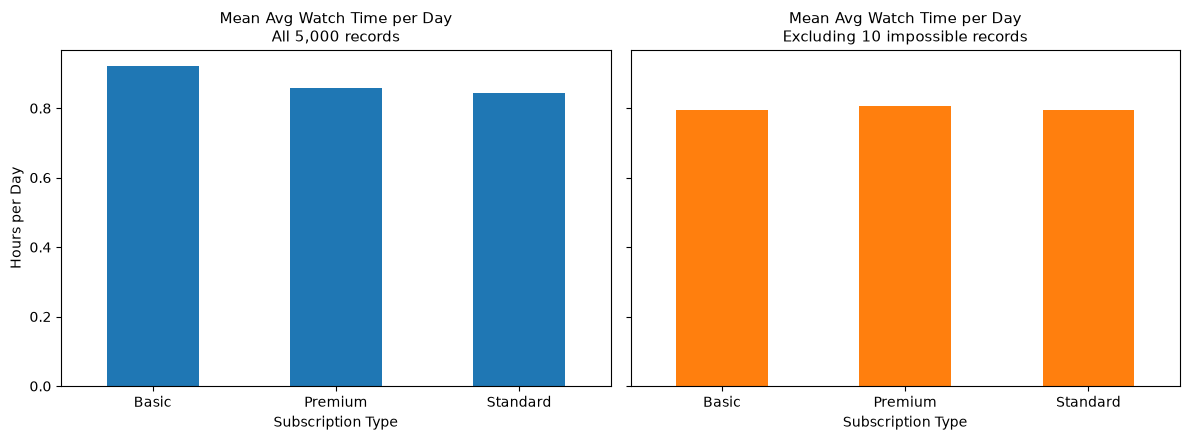

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

with_bad.plot(kind="bar", ax=ax[0], color="tab:blue")
ax[0].set_title("Mean Avg Watch Time per Day\nAll 5,000 records", fontsize=11)
ax[0].set_ylabel("Hours per Day")
ax[0].set_xlabel("Subscription Type")
ax[0].tick_params(axis="x", rotation=0)

without_bad.plot(kind="bar", ax=ax[1], color="tab:orange")
ax[1].set_title("Mean Avg Watch Time per Day\nExcluding 10 impossible records", fontsize=11)
ax[1].set_xlabel("Subscription Type")
ax[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

All ten impossible records carry a `last_login_days` of 0 or 1, which looks like a
divide by a very small number during generation rather than genuine behavior. Four of the
ten sit in the Basic group.

Dropping those ten rows out of 5,000 reverses the ordering of the classmate's bar chart. Basic
falls from 0.9221 to 0.7959 and Premium rises to the top at 0.8063. The medians were
already nearly identical at 0.29, 0.30, and 0.29 hours, so the tier gap was never really
there. This is why I did not build my filter around `avg_watch_time_per_day`.

### 1d. Answering the classmate's open question about the even category counts

The classmate asked whether the near equal subscription counts are coincidental or a product of
how the data was assembled. A uniformity check across every categorical variable
addresses it. Expected count under a uniform distribution is simply the row count divided
by the number of categories.

In [8]:
categoricals = ["gender", "subscription_type", "region", "device",
                "payment_method", "favorite_genre"]

rows = []
for column in categoricals:
    observed = netflix[column].value_counts()
    expected = len(netflix) / observed.size
    chi_square = (((observed - expected) ** 2) / expected).sum()
    rows.append({
        "variable": column,
        "categories": observed.size,
        "expected_each": round(expected, 1),
        "observed_min": observed.min(),
        "observed_max": observed.max(),
        "max_deviation_pct": round((observed - expected).abs().max() / expected * 100, 2),
        "chi_square": round(chi_square, 3),
    })

pd.DataFrame(rows)

,variable,categories,expected_each,observed_min,observed_max,max_deviation_pct,chi_square
0,gender,3,1666.7,1635,1711,2.66,1.877
1,subscription_type,3,1666.7,1646,1693,1.58,0.692
2,region,6,833.3,765,873,8.20,10.401
3,device,5,1000.0,949,1048,5.10,5.006
4,payment_method,5,1000.0,973,1030,3.00,2.906
5,favorite_genre,7,714.3,685,731,4.10,2.522


In [9]:
# The same question for the discrete numeric variables
for column in ["age", "last_login_days", "number_of_profiles"]:
    observed = netflix[column].value_counts()
    expected = len(netflix) / observed.size
    print(f"{column:20s} range {netflix[column].min()} to {netflix[column].max()}"
          f" | {observed.size} distinct values"
          f" | expected {expected:.1f} each"
          f" | observed {observed.min()} to {observed.max()}")
print()
print("Overall churn rate:", round(netflix["churned"].mean() * 100, 2), "percent")

age                  range 18 to 70 | 53 distinct values | expected 94.3 each | observed 72 to 111
last_login_days      range 0 to 60 | 61 distinct values | expected 82.0 each | observed 60 to 102
number_of_profiles   range 1 to 5 | 5 distinct values | expected 1000.0 each | observed 972 to 1034

Overall churn rate: 50.3 percent


Every categorical variable sits within a few percent of a perfectly even split, and
`age` is close to flat across all 53 values from 18 to 70. Real subscriber bases are not
uniform in age, region, or payment method, and the overall churn rate of 50.3 percent is
roughly 25 times Netflix's reported monthly churn of about 2 percent [1], [2]. Taken
together this points to a generated data set rather than a sample of real customers. That
does not make it useless for practicing techniques, but it does mean the findings describe
the generator and not Netflix.

## 2. Filter using more than one variable

**Filter:** retained customers (`churned == 0`) who have not logged in for at least 21
days (`last_login_days >= 21`) and who watch less than the retained median of 13.86 hours
(`watch_hours < 13.86`).

**Logic:** section 1a established that low watch hours and long absences are the two
strongest churn signals in the file. This filter applies those two thresholds to customers
who have not yet churned, which isolates subscribers who are still paying but already
behave like the churned group. That is a retention target list rather than an arbitrary
slice.

In [10]:
retained_median = netflix.loc[netflix["churned"] == 0, "watch_hours"].median()
print("Median watch hours among retained customers:", retained_median)

before = len(netflix)

at_risk = netflix[
    (netflix["churned"] == 0)
    & (netflix["last_login_days"] >= 21)
    & (netflix["watch_hours"] < retained_median)
].copy()

after = len(at_risk)

print("Records before filter:", before)
print("Records after filter: ", after)
print("Observations removed: ", before - after,
      f"({(before - after) / before * 100:.1f} percent)")

Median watch hours among retained customers: 13.86
Records before filter: 5000
Records after filter:  431
Observations removed:  4569 (91.4 percent)


In [11]:
at_risk[["age", "watch_hours", "last_login_days", "number_of_profiles"]].describe().round(2)

,age,watch_hours,last_login_days,number_of_profiles
count,431.00,431.00,431.00,431.00
mean,42.68,8.02,31.79,3.74
std,15.59,3.23,10.84,1.27
min,18.00,0.10,21.00,1.00
25%,29.00,5.94,24.00,3.00
50%,41.00,7.91,27.00,4.00
75%,57.00,10.54,37.00,5.00
max,70.00,13.80,60.00,5.00


In [12]:
at_risk["subscription_type"].value_counts()

subscription_type
Premium     195
Standard    176
Basic        60
Name: count, dtype: int64

The filter keeps **431 records and removes 4,569**, which is 91.4 percent of the file.
The cohort is weighted toward the paid tiers, with 195 Premium and 176 Standard against
only 60 Basic, which is the opposite of what the tier churn rates in section 1b would
predict and makes the group more interesting from a revenue standpoint.

## 3. Add a column

I added two.

**`watch_hours_per_profile`** divides watch hours by the number of profiles on the
account. Purpose: it normalizes engagement by household size so a five profile family is
not compared directly against a single viewer. The raw `watch_hours` column treats a
household of five that watches 10 hours as equivalent to one person watching 10 hours,
which are very different situations for a retention team. This is also the only variable
in the frame that combines two existing columns into genuinely new information rather than
restating one of them.

**`annual_revenue_at_risk`** multiplies the monthly fee by twelve. Purpose: it converts
the cohort from a row count into a dollar figure, so the size of the retention problem can
be stated in terms a business audience acts on.

In [13]:
at_risk["watch_hours_per_profile"] = (
    at_risk["watch_hours"] / at_risk["number_of_profiles"]
).round(3)

at_risk["annual_revenue_at_risk"] = (at_risk["monthly_fee"] * 12).round(2)

at_risk[["watch_hours", "number_of_profiles", "watch_hours_per_profile",
         "monthly_fee", "annual_revenue_at_risk"]].head(10)

,watch_hours,number_of_profiles,watch_hours_per_profile,monthly_fee,annual_revenue_at_risk
5,13.80,3,4.600,13.99,167.88
12,7.92,1,7.920,13.99,167.88
18,7.67,4,1.918,17.99,215.88
30,7.62,3,2.540,13.99,167.88
50,8.79,4,2.198,17.99,215.88
80,3.56,4,0.890,13.99,167.88
83,9.91,2,4.955,17.99,215.88
88,9.69,4,2.422,8.99,107.88
94,13.38,4,3.345,17.99,215.88
102,9.87,3,3.290,13.99,167.88


In [14]:
print("Total annual revenue at risk in this cohort: $",
      f"{at_risk['annual_revenue_at_risk'].sum():,.2f}", sep="")
print("Mean per customer:                            $",
      f"{at_risk['annual_revenue_at_risk'].mean():,.2f}", sep="")
print()
print(at_risk["watch_hours_per_profile"].describe().round(3))

Total annual revenue at risk in this cohort: $78,116.28
Mean per customer:                            $181.24

count    431.000
mean       2.771
std        2.287
min        0.020
25%        1.427
50%        2.136
75%        3.250
max       13.720
Name: watch_hours_per_profile, dtype: float64


The 431 customers represent **\$78,116.28** in annual subscription revenue, an average
of \$181.24 each.

## 4. Drop columns

**`customer_id`** is a UUID with 5,000 distinct values across 5,000 rows. It is a record
identifier, not a feature. It cannot be grouped, correlated, or modeled, and carrying it
through an analysis only creates a risk of accidentally treating an identifier as data.

**`monthly_fee`** is dropped because of the observation the classmate made in her own post. She
found that the fee has no variability beyond the subscription level. A crosstab confirms
it is a perfect one to one mapping, so the column is a restatement of `subscription_type`
in dollars. Keeping both would put two copies of the same information in the frame, and
the fee is already preserved in annualized form by `annual_revenue_at_risk`.

In [15]:
# Confirming the one to one mapping the classmate identified
pd.crosstab(netflix["subscription_type"], netflix["monthly_fee"])

monthly_fee,8.99,13.99,17.99
subscription_type,,,
Basic,1661,0,0
Premium,0,0,1693
Standard,0,1646,0


In [16]:
print("Columns before dropping:", at_risk.shape[1])

at_risk.drop(columns=["customer_id", "monthly_fee"], inplace=True)

print("Columns after dropping: ", at_risk.shape[1])
print()
print("Remaining columns:")
print(list(at_risk.columns))

Columns before dropping: 16
Columns after dropping:  14

Remaining columns:
['age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days', 'region', 'device', 'churned', 'payment_method', 'number_of_profiles', 'avg_watch_time_per_day', 'favorite_genre', 'watch_hours_per_profile', 'annual_revenue_at_risk']


## 5. IQR outlier boundaries and removal

I ran the IQR technique on `watch_hours_per_profile`, the variable created in section 3.
Running it on `watch_hours` would be circular, because the filter in section 2 already
truncated that column at 13.86 hours and therefore removed the upper tail by construction.

**The calculation.** The interquartile range is the spread of the middle half of the data,
`IQR = Q3 - Q1`, where Q1 is the 25th percentile and Q3 the 75th. The standard fences sit
one and a half interquartile ranges beyond each quartile:

\[ \text{lower} = Q1 - 1.5 \times IQR \qquad \text{upper} = Q3 + 1.5 \times IQR \]

Any value outside those fences is flagged as a possible outlier. The logic is that a
point more than one and a half spreads away from the middle half is far enough from the
bulk of the distribution to be treated as unusual. The method uses quartiles rather than
the mean and standard deviation, so the boundaries are not themselves dragged outward by
the extreme values they are meant to detect.

In [17]:
q1 = at_risk["watch_hours_per_profile"].quantile(0.25)
q3 = at_risk["watch_hours_per_profile"].quantile(0.75)
iqr = q3 - q1

lower_boundary = q1 - 1.5 * iqr
upper_boundary = q3 + 1.5 * iqr

print("Q1 (25th percentile):", round(q1, 4))
print("Q3 (75th percentile):", round(q3, 4))
print("IQR (Q3 - Q1):       ", round(iqr, 4))
print()
print("Lower boundary (Q1 - 1.5 * IQR):", round(lower_boundary, 4))
print("Upper boundary (Q3 + 1.5 * IQR):", round(upper_boundary, 4))

Q1 (25th percentile): 1.427
Q3 (75th percentile): 3.2495
IQR (Q3 - Q1):        1.8225

Lower boundary (Q1 - 1.5 * IQR): -1.3068
Upper boundary (Q3 + 1.5 * IQR): 5.9833


In [18]:
outliers = at_risk[
    (at_risk["watch_hours_per_profile"] < lower_boundary)
    | (at_risk["watch_hours_per_profile"] > upper_boundary)
]

print("Possible outliers identified:", len(outliers))
print("Below the lower boundary:", (at_risk["watch_hours_per_profile"] < lower_boundary).sum())
print("Above the upper boundary:", (at_risk["watch_hours_per_profile"] > upper_boundary).sum())
print()
print(outliers[["watch_hours", "number_of_profiles", "watch_hours_per_profile"]]
      .sort_values("watch_hours_per_profile", ascending=False)
      .head(10)
      .to_string())

Possible outliers identified: 39
Below the lower boundary: 0
Above the upper boundary: 39

      watch_hours  number_of_profiles  watch_hours_per_profile
4124        13.72                   1                    13.72
1491        13.38                   1                    13.38
1234        12.19                   1                    12.19
4490        12.13                   1                    12.13
2940        12.06                   1                    12.06
4525        12.02                   1                    12.02
2051        11.48                   1                    11.48
3651        11.07                   1                    11.07
4311        10.71                   1                    10.71
789         10.67                   1                    10.67


In [19]:
# What do the flagged records have in common?
print("Profile counts among the 39 flagged records:")
print(outliers["number_of_profiles"].value_counts().sort_index())
print()
print("Profile counts across the whole 431 record cohort:")
print(at_risk["number_of_profiles"].value_counts().sort_index())
print()
print("Mean raw watch_hours of the flagged records:",
      round(outliers["watch_hours"].mean(), 2))

Profile counts among the 39 flagged records:
number_of_profiles
1    33
2     6
Name: count, dtype: int64

Profile counts across the whole 431 record cohort:
number_of_profiles
1     39
2     45
3     48
4    155
5    144
Name: count, dtype: int64

Mean raw watch_hours of the flagged records: 9.59


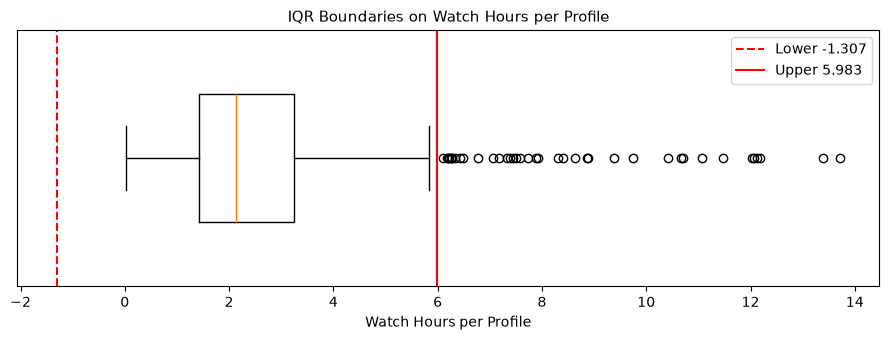

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.boxplot(at_risk["watch_hours_per_profile"], vert=False, widths=0.5)
ax.axvline(lower_boundary, color="red", linestyle="--", label=f"Lower {lower_boundary:.3f}")
ax.axvline(upper_boundary, color="red", linestyle="-", label=f"Upper {upper_boundary:.3f}")
ax.set_xlabel("Watch Hours per Profile")
ax.set_yticks([])
ax.set_title("IQR Boundaries on Watch Hours per Profile", fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()

In [21]:
records_before = len(at_risk)

at_risk.drop(outliers.index, inplace=True)

print("Records before outlier removal:", records_before)
print("Records after outlier removal: ", len(at_risk))
print("Observations removed:          ", records_before - len(at_risk))
print()
print("Final shape:", at_risk.shape)

Records before outlier removal: 431
Records after outlier removal:  392
Observations removed:           39

Final shape: (392, 14)


In [22]:
at_risk[["watch_hours", "watch_hours_per_profile", "annual_revenue_at_risk"]].describe().round(3)

,watch_hours,watch_hours_per_profile,annual_revenue_at_risk
count,392.000,392.000,392.000
mean,7.859,2.187,181.502
std,3.259,1.217,37.162
min,0.100,0.020,107.880
25%,5.698,1.340,167.880
50%,7.710,2.018,167.880
75%,10.392,2.834,215.880
max,13.800,5.825,215.880


**Results.** Q1 is 1.427 and Q3 is 3.250, giving an IQR of 1.823. The boundaries land
at **-1.307 and 5.983** hours per profile, and **39 observations** fell outside them,
leaving 392 records.

Every one of the 39 sits above the upper fence. The lower boundary is negative, and watch
hours can never be negative, so this variable cannot produce a low side outlier at all.
That is worth stating plainly rather than reporting the number as if it were meaningful.
It happens whenever a non negative variable is right skewed enough that 1.5 interquartile
ranges below Q1 falls past zero, and it means the fence is doing work on one side only.

The composition of the 39 is the more useful result. Thirty three of them are single
profile accounts and the other six have two profiles, and the cohort contains only 39
single profile accounts in total. The fence therefore flagged 33 of 39 single profile
subscribers while clearing almost every household with four or five profiles. Their raw
`watch_hours` average 9.59, which is unremarkable. What made them extreme was dividing by
a denominator of 1.

So on this variable the IQR technique is mostly detecting household size, a structural
feature of the account, rather than unusual viewing behavior. That is a caution worth
carrying into any engineered ratio: when the denominator has a small integer range, the
ratio inherits its shape, and the fences end up sorting on the denominator. Unlike the ten
impossible records in section 1c, which describe more than 24 hours of viewing in a day
and are genuinely invalid, these 39 are legitimate values and a modeler might well keep
them and control for profile count instead.

## 6. References

[1] Antenna, "Antenna's 2024 Top Subscription Insights: Net Churn," Sep. 2024. [Online].
Available: https://www.antenna.live/insights/antennas-2024-top-subscription-insights-net-churn

[2] Antenna, "Why Subscriber Tenure Matters," Antenna Insights. [Online]. Available:
https://www.antenna.live/insights/why-subscriber-tenure-matters

[3] Netflix, "Plans and Pricing," Netflix Help Center. [Online]. Available:
https://help.netflix.com/en/node/24926

[4] B. Allyn, "Netflix ends its cheapest ad-free subscription," NPR, Jul. 19, 2024.
[Online]. Available: https://www.npr.org/2024/07/19/nx-s1-5046733/netflix-ends-its-cheapest-ad-free-subscription

[5] A. Wadood, "Netflix Customer Churn dataset," Kaggle, Jul. 5, 2025. [Online].
Available: https://www.kaggle.com/datasets/abdulwadood11220/netflix-customer-churn-dataset

[6] IBM, "What is customer churn?" IBM Think Topics. [Online]. Available:
https://www.ibm.com/think/topics/customer-churn